# Chapter 17: Case study: a quadrotor, end to end

One quadrotor, one mission, every block of the recipe connected in one simulation.
The vehicle is carried by hand while its filter starts from a bad estimate, thrown upside down,
rights itself, flies a minimum-snap course through an obstacle that the plan did not know about,
in a gust, with a package strapped on off-center, and ends in hover at a target.

This notebook is self-contained: NumPy, SciPy and Matplotlib only. The model and the controllers
are copied from the robot model library (`case_studies/robots`) and from the scripts that verified
the earlier chapters, and `verify/ch17.py` checks every copy against its original.

Notation. $R$ maps body to world, $\dot R = R\,\Omega^\wedge$, errors take the actual
configuration first: $e_R$ is built from $R_d^\top R$. An estimate carries a hat, in code `Rhat`,
`xhat`. The input is $u = (f, \tau)$.

**To change the mission**, edit the fields of `Mission` (waypoints, obstacle, gust, package,
sensors, limits) and run the notebook again.

In [1]:
from dataclasses import dataclass, field, replace
import math

import numpy as np
import matplotlib.pyplot as plt

E1, E2, E3 = np.eye(3)
np.set_printoptions(precision=4, suppress=True)

## 1. The mission

Every number of the mission is a field of `Mission`. Times are in seconds from the moment the
filter is switched on. The vehicle is in the operator's hand until `t_carry`, the reference waits
at the first waypoint for `t_hold`, the course takes `t_course`, and the vehicle then hovers at the
target for `t_rest`.

In [2]:
def unit(x):
    return np.asarray(x, float) / np.linalg.norm(x)


def hat(x):
    """hat(x) y = x cross y."""
    return np.array([[0.0, -x[2], x[1]], [x[2], 0.0, -x[0]], [-x[1], x[0], 0.0]])


def vee(A):
    """Inverse of hat."""
    return np.array([A[2, 1], A[0, 2], A[1, 0]])


def expm_so3(x):
    """exp(hat(x)), Rodrigues' formula (prop2-rodrigues)."""
    angle = np.linalg.norm(x)
    if angle < 1e-12:
        return np.eye(3) + hat(x)
    K = hat(x / angle)
    return np.eye(3) + np.sin(angle) * K + (1.0 - np.cos(angle)) * K @ K


def log_so3(R):
    """Rotation vector of R: log(R) with the vee map applied."""
    angle = np.arccos(np.clip((np.trace(R) - 1.0) / 2.0, -1.0, 1.0))
    if angle < 1e-9:
        return vee(R - R.T) / 2.0
    if np.pi - angle < 1e-6:
        S = (R + np.eye(3)) / 2.0
        a = np.sqrt(np.clip(np.diag(S), 0.0, None))
        k = int(np.argmax(a))
        return angle * S[:, k] / a[k]
    return angle * vee(R - R.T) / (2.0 * np.sin(angle))


def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])


@dataclass
class Mission:
    """Every number of the mission. Change one and fly again."""
    h: float = 0.005                               # s: time step, IMU period, sampling period
    t_carry: float = 6.0                           # s: carried by hand, motors off, filter running
    t_hold: float = 2.5                            # s: after the release the reference waits at the first waypoint
    t_course: float = 7.5                          # s: duration of the minimum-snap course
    t_rest: float = 2.0                            # s: hover at the target
    waypoints: np.ndarray = field(default_factory=lambda: np.array(
        [[0.0, 0.0, 3.0], [2.5, 1.2, 3.6], [5.0, -0.6, 3.0], [7.5, 0.8, 2.4], [9.0, 0.0, 2.0]]))
    psi_f: float = np.pi / 2                       # rad: heading at the end of the course
    # the carry: from the pad to the release point, then a throw with a flip
    x_pad: np.ndarray = field(default_factory=lambda: np.array([-1.5, -1.0, 1.0]))
    psi_pad: float = np.radians(140.0)             # heading on the pad, which the filter does not know
    x_release: np.ndarray = field(default_factory=lambda: np.array([0.0, 0.0, 2.2]))
    v_release: np.ndarray = field(default_factory=lambda: np.array([0.4, 0.0, 3.0]))
    flip: float = np.radians(160.0)                # the throw turns the vehicle by this much
    flip_axis: np.ndarray = field(default_factory=lambda: unit([1.0, 0.4, 0.2]))
    t_flip: float = 0.8                            # s: duration of the flip, at the end of the carry
    # what the filter believes when it is switched on: level, at rest, at the origin, heading zero
    sig0: tuple = (1.0, 2.0, 2.5)                  # initial standard deviations: v (m/s), x (m), R (rad)
    # the package: weight known, place unknown
    m_add: float = 0.8                             # kg
    r_add: np.ndarray = field(default_factory=lambda: np.array([0.20, -0.12, -0.05]))   # m, body frame
    # the gust: a crosswind force (world frame) and a torque (body frame)
    gust_force: float = 3.0                        # N, peak
    gust_window: tuple = (1.0, 6.5)                # s, counted from the start of the course
    gust_torque: float = 2.0                       # times the gust torque of Chapter 8
    # the obstacle
    x_o: np.ndarray = field(default_factory=lambda: np.array([4.2, 0.9, 3.5]))
    r_o: float = 0.6
    beta: float = 1.8
    sigma_k: tuple = (0.25, 4.0, 0.0)              # sigma(p) = k1 tanh((k3 - k2 p) / 2)
    alpha: tuple = (3.0, 6.0)
    w_tau: float = 40.0
    # actuator limits
    f_max: float = 100.0                           # N
    tau_max: float = 8.0                           # N·m, each axis
    # sensors
    sig_g: float = 0.01                            # rad/s per sample
    sig_a: float = 0.1                             # m/s² per sample
    sig_y: float = 0.03                            # m per landmark reading
    every: int = 4                                 # a landmark reading every `every` steps
    landmarks: np.ndarray = field(default_factory=lambda: np.array(
        [[-1.0, -3.0, 0.0], [10.0, -3.0, 0.5], [10.0, 3.0, 0.0], [-1.0, 3.0, 1.0]]))
    # gains: Lee's position gains, attitude gains scaled by (kappa^2, kappa)
    kappa: float = 2.0
    # adaptation (Chapter 8)
    k_Delta: float = 4000.0
    k_f: float = 20.0
    Delta_max: float = 4.0
    c: float = 0.1
    seed: int = 17


    @property
    def t_start(self):
        return self.t_carry + self.t_hold

    @property
    def t_end(self):
        return self.t_start + self.t_course + self.t_rest

## 2. A state that is a group element

The configuration is a position and an attitude, $(x, R) \in \mathrm{SE}(3)$, stored as a vector
and a rotation matrix. The model is $m\ddot x = f R e_3 - m g\,e_3$,
$J\dot\Omega + \Omega\times J\Omega = \tau$. The class below is the library's quadrotor
(`robots.get("quadrotor")`) reduced to what this notebook needs, plus three things the controller
does not know: the thrust misses the center of mass by `rho`, a force `F_e` acts in the world frame
and a torque `tau_e` in the body frame. `step` is the library's step: fourth-order Runge-Kutta
stages on one increment per factor, then $R_{k+1} = R_k\exp(h\,\Omega_k^\wedge)$.

In [3]:
@dataclass
class Params:
    """The vehicle of Chapter 6 (Lee, Leok and McClamroch, 2010). Copied from the library."""
    m: float = 4.34                                                                    # kg
    J: np.ndarray = field(default_factory=lambda: np.diag([0.0820, 0.0845, 0.1377]))  # kg·m²
    g: float = 9.81


@dataclass
class Gains:
    """Gains of the cascade in Chapter 6, for the default vehicle. Copied from the library."""
    k_x: float = 16 * 4.34
    k_v: float = 5.6 * 4.34
    k_R: float = 8.81
    k_Omega: float = 2.54


@dataclass
class State:
    x: np.ndarray = field(default_factory=lambda: np.zeros(3))      # position, world frame
    v: np.ndarray = field(default_factory=lambda: np.zeros(3))      # velocity, world frame
    R: np.ndarray = field(default_factory=lambda: np.eye(3))        # attitude, body to world
    Omega: np.ndarray = field(default_factory=lambda: np.zeros(3))  # body angular velocity


def _dexpinv(x, y):
    """Rate of the rotation vector x of R = R_k exp(hat(x)) when the body angular velocity is y."""
    return y + 0.5 * np.cross(x, y) + np.cross(x, np.cross(x, y)) / 12.0


class LoadedQuadrotor:
    """eq4-quadrotor, with rho, F_e and tau_e. With all three zero it is the library model."""

    def __init__(self, params):
        self.params = params
        self.rho, self.F_e, self.tau_e = np.zeros(3), np.zeros(3), np.zeros(3)

    State = State

    def dynamics(self, state, u, params=None):
        """(v_dot, Omega_dot) for u = (f, tau)."""
        p = params or self.params
        f, tau = u
        tau = tau + f * np.cross(E3, self.rho) + self.tau_e
        v_dot = f * state.R @ E3 / p.m - p.g * E3 + self.F_e / p.m
        Omega_dot = np.linalg.solve(p.J, tau - np.cross(state.Omega, p.J @ state.Omega))
        return v_dot, Omega_dot

    def energy(self, state, params=None):
        p = params or self.params
        return (0.5 * p.m * state.v @ state.v + 0.5 * state.Omega @ p.J @ state.Omega
                + p.m * p.g * E3 @ state.x)

    def on_manifold(self, state):
        R = state.R
        return float(max(np.max(np.abs(R.T @ R - np.eye(3))), abs(np.linalg.det(R) - 1.0)))

    def step(self, state, u, h, params=None):
        """One step of the library (core.Robot.step) for the factors R^3 and SO(3), input held."""
        def slope(dx, dth, v, Om):
            at = State(x=state.x + dx, v=v, R=state.R @ expm_so3(dth), Omega=Om)
            v_dot, Om_dot = self.dynamics(at, u, params)
            return v, _dexpinv(dth, Om), v_dot, Om_dot

        z = np.zeros(3)
        k1 = slope(z, z, state.v, state.Omega)
        k2 = slope(*(a + h / 2 * b for a, b in zip((z, z, state.v, state.Omega), k1)))
        k3 = slope(*(a + h / 2 * b for a, b in zip((z, z, state.v, state.Omega), k2)))
        k4 = slope(*(a + h * b for a, b in zip((z, z, state.v, state.Omega), k3)))
        dx, dth, dv, dOm = (h / 6 * (a + 2 * b + 2 * c + d) for a, b, c, d in zip(k1, k2, k3, k4))
        return State(x=state.x + dx, v=state.v + dv, R=state.R @ expm_so3(dth), Omega=state.Omega + dOm)


def believed(ms):
    """Parameters the controller believes: the total mass, and the inertia of the bare vehicle."""
    p = Params()
    return replace(p, m=p.m + ms.m_add)


def true_params(ms):
    """The loaded vehicle about its own center of mass."""
    p = Params()
    m = p.m + ms.m_add
    mu = p.m * ms.m_add / m                        # reduced mass
    r = ms.r_add
    return replace(p, m=m, J=p.J + mu * ((r @ r) * np.eye(3) - np.outer(r, r))), ms.m_add / m * r


def gains(ms):
    k = Gains()
    return replace(k, k_R=ms.kappa**2 * k.k_R, k_Omega=ms.kappa * k.k_Omega)

In [4]:
# --- run
ms = Mission()
p_true, rho = true_params(ms)
print("total mass", believed(ms).m, "kg, hover thrust", round(believed(ms).m * 9.81, 2), "N")
print("center of mass moved by", np.round(1e3 * rho, 1), "mm")
print("torque of the hover thrust about it", np.round(believed(ms).m * 9.81 * np.cross(E3, rho), 3), "N·m")

total mass 5.14 kg, hover thrust 50.42 N
center of mass moved by [ 31.1 -18.7  -7.8] mm
torque of the hover thrust about it [ 0.942  1.57  -0.   ] N·m


## 3. Three errors, chosen once

The attitude error function $\Psi_R = \tfrac12\operatorname{tr}(I - R_d^\top R)$, its error vector
$e_R = \tfrac12(R_d^\top R - R^\top R_d)^\vee$ and the velocity error
$e_\Omega = \Omega - R^\top R_d\,\Omega_d$ are used three times below: between vehicle and
reference (the cascade), between state predictor and vehicle (adaptation), and, as the logarithm of
$\hat X X^{-1}$, between estimate and truth (the filter). The attitude law is eq6-law.

In [5]:
def Psi_R(R, Rd):
    return 0.5 * np.trace(np.eye(3) - Rd.T @ R)


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)


def e_Omega(R, Omega, Rd, Omegad):
    return Omega - R.T @ Rd @ Omegad


def attitude_tracking_torque(R, Omega, Rd, Omegad, Omegad_dot, J, k_R, k_Omega):
    """The attitude tracking law, eq6-law:

    tau = -k_R e_R - k_Omega e_Omega
          + Omega x J Omega - J (Omega x R^T Rd Omegad - R^T Rd Omegad_dot).
    """
    return (-k_R * e_R(R, Rd) - k_Omega * e_Omega(R, Omega, Rd, Omegad)
            + np.cross(Omega, J @ Omega)
            - J @ (np.cross(Omega, R.T @ Rd @ Omegad) - R.T @ Rd @ Omegad_dot))


def desired_attitude(F, heading):
    """eq6-Rd: third axis along F, first axis as close to the heading direction as
    that allows. heading is the unit vector R_z(psi_d) e1, with psi_d the desired
    heading (not the Euler yaw, unless the roll or the pitch is zero)."""
    b3 = unit(F)
    b2 = unit(np.cross(b3, heading))
    return np.column_stack([np.cross(b2, b3), b2, b3])


def desired_attitude_rates(F, F1, F2, hd, hd1, hd2, d=1e-4):
    """Rd, Omegad and Omegad_dot from F_d, the heading direction and their first two time
    derivatives, by central differences of eq6-Rd along the second-order curve."""
    def along(s):
        return desired_attitude(F + s * F1 + 0.5 * s * s * F2, hd + s * hd1 + 0.5 * s * s * hd2)

    Rd, Rp, Rm = along(0.0), along(d), along(-d)
    W = Rd.T @ (Rp - Rm) / (2 * d)
    Omegad = vee(0.5 * (W - W.T))
    W2 = Rd.T @ (Rp - 2 * Rd + Rm) / d**2 - hat(Omegad) @ hat(Omegad)
    return Rd, Omegad, vee(0.5 * (W2 - W2.T))

## 4. A plan in flat outputs

The reference is a minimum-snap curve through the waypoints (eq10-minsnap), found from one linear
system, and a heading that turns smoothly. The flat map (eq10-quad-map) then gives the attitude,
the angular velocity, the thrust and the torque along it. Feasibility is checked on those.

In [6]:
def derivs(a):
    """The time derivatives [a, a', a'', ...] of a jet."""
    return np.array([math.factorial(k) * a[k] for k in range(len(a))])


def _basis(s, k, deg):
    """Row of d^k/ds^k of (1, s, ..., s^deg)."""
    row = np.zeros(deg + 1)
    for j in range(k, deg + 1):
        row[j] = math.factorial(j) / math.factorial(j - k) * s ** (j - k)
    return row


def _constraints(n_seg, dur, r, smooth):
    """Linear constraints A c = b(w) on the stacked coefficients of one axis:
    interpolation, rest at both ends (derivatives 1..r-1 zero) and continuity of
    derivatives 1..smooth at the interior waypoints. Returns A and a function b(w)."""
    deg, rows, kinds = 2 * r - 1, [], []

    def row(i, s, k):
        z = np.zeros(n_seg * (deg + 1))
        z[i * (deg + 1):(i + 1) * (deg + 1)] = _basis(s, k, deg) / dur[i] ** k
        return z

    for i in range(n_seg):
        rows += [row(i, 0.0, 0), row(i, 1.0, 0)]
        kinds += [("w", i), ("w", i + 1)]
    for k in range(1, r):
        rows += [row(0, 0.0, k), row(n_seg - 1, 1.0, k)]
        kinds += [("0",), ("0",)]
    for i in range(n_seg - 1):
        for k in range(1, smooth + 1):
            rows.append(row(i, 1.0, k) - row(i + 1, 0.0, k))
            kinds.append(("0",))
    A = np.array(rows)

    def b(w):
        return np.array([w[kd[1]] if kd[0] == "w" else 0.0 for kd in kinds])
    return A, b


def _cost(n_seg, dur, r):
    """P with c' P c = integral of (x^(r))^2 over all segments, one axis."""
    deg = 2 * r - 1
    P = np.zeros((n_seg * (deg + 1),) * 2)
    for i in range(n_seg):
        for j in range(r, deg + 1):
            for k in range(r, deg + 1):
                cj = math.factorial(j) / math.factorial(j - r)
                ck_ = math.factorial(k) / math.factorial(k - r)
                P[i * (deg + 1) + j, i * (deg + 1) + k] = cj * ck_ / (j + k - 2 * r + 1) * dur[i] ** (1 - 2 * r)
    return P


class Spline:
    """Piecewise polynomial of degree 2 r - 1 through waypoints at given times."""

    def __init__(self, coeff, times, r):
        self.coeff, self.times, self.r = coeff, np.asarray(times, float), r   # coeff: (n_seg, deg + 1, dim)
        self.dur = np.diff(self.times)

    def jet(self, t, order):
        i = int(np.clip(np.searchsorted(self.times, t, side="right") - 1, 0, len(self.dur) - 1))
        s = (t - self.times[i]) / self.dur[i]
        deg = self.coeff.shape[1] - 1
        return np.array([_basis(s, k, deg) @ self.coeff[i] / self.dur[i] ** k / math.factorial(k)
                         for k in range(order + 1)])

    def jet_side(self, i, s, order):
        deg = self.coeff.shape[1] - 1
        return np.array([_basis(s, k, deg) @ self.coeff[i] / self.dur[i] ** k / math.factorial(k)
                         for k in range(order + 1)])

    def __call__(self, t):
        return self.jet(t, 0)[0]

    def cost(self):
        P = _cost(len(self.dur), self.dur, self.r)
        c = self.coeff.reshape(-1, self.coeff.shape[2])
        return float(np.trace(c.T @ P @ c))


def min_derivative_spline(waypoints, times, r=4, method="qp"):
    """The curve through the waypoints at the given times, at rest at both ends,
    that minimizes the integral of |x^(r)|^2 (r = 4: minimum snap).

    method "qp": quadratic program with continuity up to order r - 1 imposed,
    solved through its KKT system (eq10-minsnap).
    method "spline": no optimization. The square linear system that asks for
    continuity up to order 2 r - 2, which the minimizer has on its own."""
    w = np.asarray(waypoints, float)
    times = np.asarray(times, float)
    n_seg, dur, deg = len(w) - 1, np.diff(times), 2 * r - 1
    if method == "qp":
        A, b = _constraints(n_seg, dur, r, r - 1)
        P = _cost(n_seg, dur, r)
        KKT = np.block([[2 * P, A.T], [A, np.zeros((len(A), len(A)))]])
        sol = np.column_stack([np.linalg.solve(KKT, np.concatenate([np.zeros(P.shape[0]), b(w[:, d])]))
                               for d in range(w.shape[1])])
        c = sol[:P.shape[0]]
    else:
        A, b = _constraints(n_seg, dur, r, 2 * r - 2)
        c = np.column_stack([np.linalg.solve(A, b(w[:, d])) for d in range(w.shape[1])])
    return Spline(c.reshape(n_seg, deg + 1, w.shape[1]), times, r)


def chord_times(waypoints, t_f):
    """Waypoint times proportional to chord length, from 0 to t_f."""
    d = np.linalg.norm(np.diff(np.asarray(waypoints, float), axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(d)]) * t_f / np.sum(d)


def quadrotor_flat_closed(d, psi, psi1, psi2, p):
    """The same map in closed form, eq10-quad-map to eq10-quad-Omega3-dot.
    d = [x, x', x'', x''', x'''']."""
    F, F1, F2 = p.m * (d[2] + p.g * E3), p.m * d[3], p.m * d[4]
    f = np.linalg.norm(F)
    b3 = F / f
    c = np.array([np.cos(psi), np.sin(psi), 0.0])
    cp = np.cross(E3, c)                                     # c_dot = psi_dot cp
    b2 = np.cross(b3, c) / np.linalg.norm(np.cross(b3, c))
    b1 = np.cross(b2, b3)
    f1 = b3 @ F1
    O1, O2 = -(b2 @ F1) / f, (b1 @ F1) / f
    O3 = (O1 * (b3 @ c) + psi1 * (b2 @ cp)) / (b1 @ c)
    Om = np.array([O1, O2, O3])
    O1d = -(b2 @ F2 + 2 * f1 * O1) / f + O2 * O3
    O2d = (b1 @ F2 - 2 * f1 * O2) / f - O1 * O3
    R = np.column_stack([b1, b2, b3])
    b1d, b2d, b3d = (R @ np.cross(Om, e) for e in (E1, E2, E3))
    num = (O1d * (b3 @ c) + O1 * (b3d @ c + psi1 * (b3 @ cp)) + psi2 * (b2 @ cp)
           + psi1 * (b2d @ cp) - O3 * (b1d @ c + psi1 * (b1 @ cp)))
    Omd = np.array([O1d, O2d, num / (b1 @ c)])
    return dict(f=f, R=R, Omega=Om, Omega_dot=Omd, tau=p.J @ Omd + np.cross(Om, p.J @ Om),
                f_dot=f1, f_ddot=b3 @ F2 + f * (O1**2 + O2**2))


class Plan:
    """x_d(t) and psi_d(t): hold, minimum-snap course, hold. The flat map gives the rest."""

    def __init__(self, ms):
        self.ms, self.p = ms, believed(ms)
        self.times = chord_times(ms.waypoints, ms.t_course)
        self.spline = min_derivative_spline(ms.waypoints, self.times, r=4)

    def flat_output(self, t):
        """[x, x', x'', x''', x''''] and (psi, psi', psi'')."""
        ms = self.ms
        raw = (t - ms.t_start) / ms.t_course
        s = np.clip(raw, 0.0, 1.0)
        d = derivs(self.spline.jet(s * ms.t_course, 4))
        if raw < -1e-12 or raw > 1 + 1e-12:               # holding: only the snap jumps at the two ends
            d[1:] = 0.0
        T = ms.t_course
        psi = ms.psi_f * (10 * s**3 - 15 * s**4 + 6 * s**5)
        psi1 = ms.psi_f * (30 * s**2 - 60 * s**3 + 30 * s**4) / T
        psi2 = ms.psi_f * (60 * s - 180 * s**2 + 120 * s**3) / T**2
        return d, (psi, psi1, psi2)

    def __call__(self, t):
        """The reference tuple of the library's controller, and the flat map eq10-quad-map."""
        d, (psi, psi1, psi2) = self.flat_output(t)
        c, s = np.cos(psi), np.sin(psi)
        hd = np.array([c, s, 0.0])
        hp = np.array([-s, c, 0.0])
        ref = (d[0], d[1], d[2], d[3], d[4], hd, psi1 * hp, psi2 * hp - psi1**2 * hd)
        return ref, quadrotor_flat_closed(d, psi, psi1, psi2, self.p)

thrust over hover: 0.94 to 1.18
largest tilt 26.1 deg, largest torque 0.60 N·m
the plan passes 0.13 m from the center of a ball of radius 0.6 m


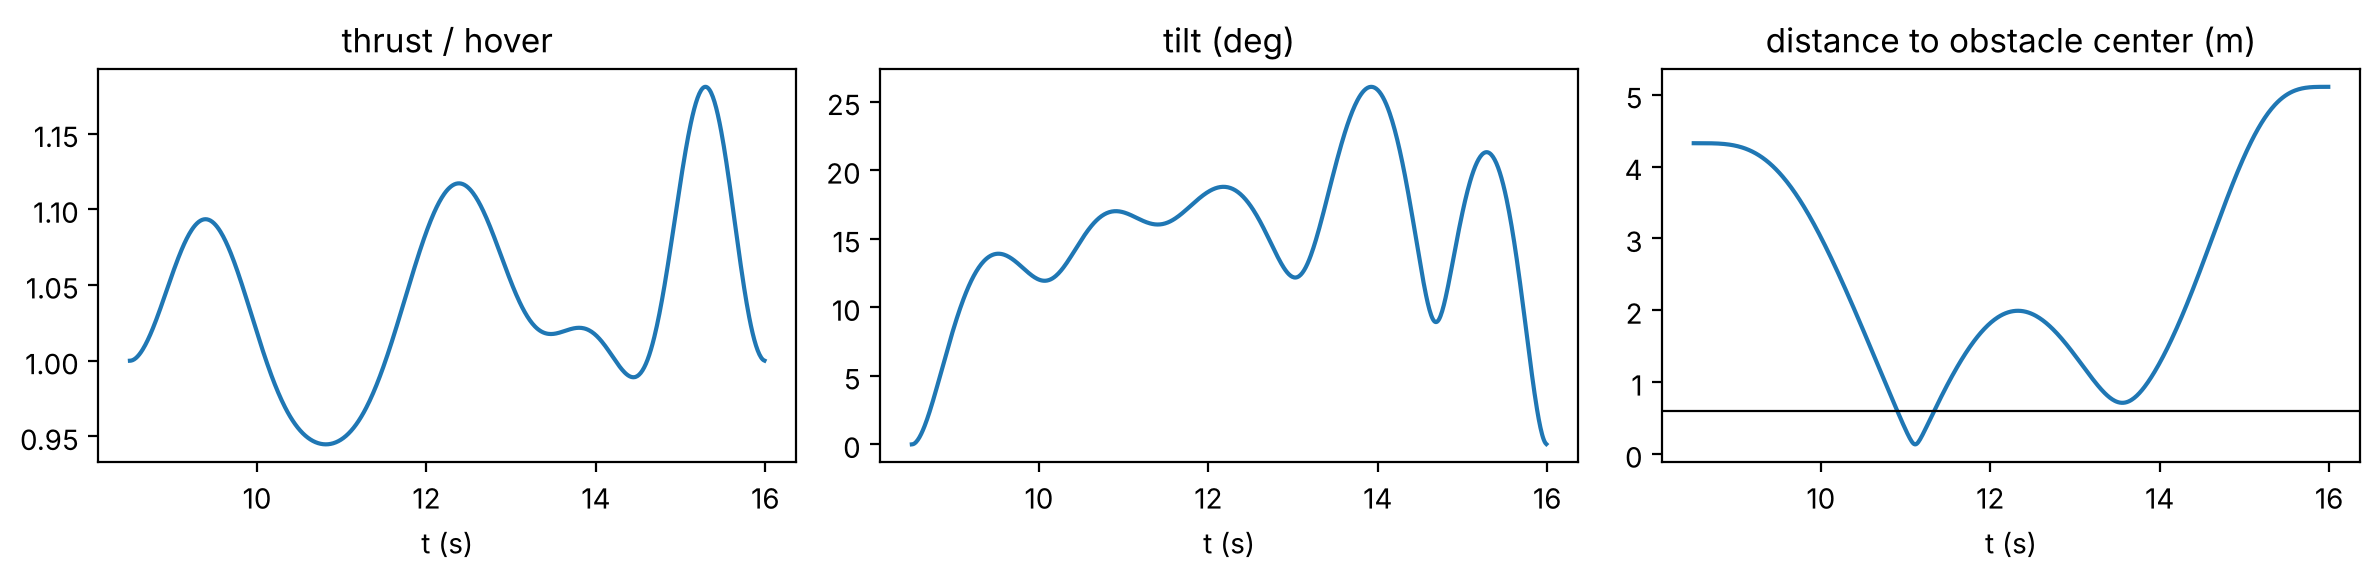

In [7]:
# --- run
plan = Plan(ms)
ts = np.arange(ms.t_start, ms.t_start + ms.t_course, 0.01)
flat = [plan(t) for t in ts]
hover = believed(ms).m * 9.81
f_plan = np.array([o["f"] for _, o in flat])
tilt_plan = np.degrees([np.arccos(o["R"][2, 2]) for _, o in flat])
tau_plan = np.array([np.linalg.norm(o["tau"]) for _, o in flat])
gap = np.array([np.linalg.norm(r[0] - ms.x_o) for r, _ in flat])
print("thrust over hover: %.2f to %.2f" % (f_plan.min() / hover, f_plan.max() / hover))
print("largest tilt %.1f deg, largest torque %.2f N·m" % (tilt_plan.max(), tau_plan.max()))
print("the plan passes %.2f m from the center of a ball of radius %.1f m" % (gap.min(), ms.r_o))
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(ts, f_plan / hover), ax[0].set_title("thrust / hover")
ax[1].plot(ts, tilt_plan), ax[1].set_title("tilt (deg)")
ax[2].plot(ts, gap), ax[2].axhline(ms.r_o, color="k", lw=0.8), ax[2].set_title("distance to obstacle center (m)")
for a in ax:
    a.set_xlabel("t (s)")
plt.tight_layout()

## 5. What the controller does not know

The package and the gust. Its weight is known, its place is not: the thrust misses the center of
mass and the inertia is wrong. L1 adaptive control (eq8-l1-law, eq8-adapt, eq8-filter) estimates the
lumped uncertainty $\Delta$. The class below is the controller of Chapter 8, and `L1Told` splits
its step in two so that the safety filter can stand between the torque it proposes and the torque
that is applied. The state predictor is told what was changed.

In [8]:
def feedforward(R, Om, Rd, Omd, Omd_dot, J):
    """Om x J Om - J (hat(Om) R^T Rd Omd - R^T Rd Omd_dot): cancels everything but the PD term."""
    return np.cross(Om, J @ Om) - J @ (hat(Om) @ R.T @ Rd @ Omd - R.T @ Rd @ Omd_dot)


def proj(theta, y, bound, eps=0.1):
    """Smooth projection of Lavretsky and Gibson: acts for |theta| > bound / sqrt(1 + eps), keeps |theta| <= bound."""
    f = ((1 + eps) * theta @ theta - bound**2) / (eps * bound**2)
    grad = 2 * (1 + eps) * theta / (eps * bound**2)
    if f > 0 and y @ grad > 0:
        return y - grad * (grad @ y) / (grad @ grad) * f
    return y


class L1Attitude:
    """Geometric L1 adaptive attitude control (Kotaru 2022, ch. 3), book notation.

    State: predictor (Rp, Omp), estimate Dhat, filtered estimate Df.
    """

    def __init__(self, R0, Om0, h, k_Delta=4000.0, k_f=20.0, bound=3.0, c=0.01,
                 J=None, k_R=1.0, k_Omega=1.0, k_Rtilde=1.0, k_Omegatilde=1.0):
        self.Rp, self.Omp = R0.copy(), Om0.copy()
        self.Dhat, self.Df = np.zeros(3), np.zeros(3)
        self.h, self.k_Delta, self.k_f, self.bound, self.c = h, k_Delta, k_f, bound, c
        self.J, self.Ji = J, np.linalg.inv(J)
        self.k_R, self.k_Omega, self.k_Rtilde, self.k_Omegatilde = k_R, k_Omega, k_Rtilde, k_Omegatilde

    def errors(self, R, Om):
        """Prediction errors: the predictor plays 'actual', the plant plays 'desired'."""
        return e_R(self.Rp, R), e_Omega(self.Rp, self.Omp, R, Om), Psi_R(self.Rp, R)

    def Xi(self, R):
        return self.J @ self.Rp.T @ R @ self.Ji @ R.T @ self.Rp

    def torques(self, R, Om, Rd, Omd, Omd_dot):
        """Return (tau, tau_fb, tau_fb_p) from the current controller state. Does not advance it."""
        J, Ji, Rp, Omp = self.J, self.Ji, self.Rp, self.Omp
        eRt, eOmt, _ = self.errors(R, Om)
        pd_p = -self.k_R * e_R(Rp, Rd) - self.k_Omega * e_Omega(Rp, Omp, Rd, Omd)
        tau_fb_p = pd_p + self.Xi(R) @ self.Dhat - self.Df
        eOm = e_Omega(R, Om, Rd, Omd)
        tau_fb = (J @ R.T @ Rp @ Ji @ (pd_p - self.Df + self.k_Rtilde * eRt + self.k_Omegatilde * eOmt)
              + J @ R.T @ Rp @ hat(eOmt) @ Rp.T @ R @ eOm)
        tau = tau_fb + feedforward(R, Om, Rd, Omd, Omd_dot, J)
        return tau, tau_fb, tau_fb_p

    def adapt_direction(self, R, Om):
        eRt, eOmt, _ = self.errors(R, Om)
        Xi = self.Xi(R)
        return -(Xi.T @ eOmt + self.c * Xi.T @ self.Ji.T @ eRt)

    def step(self, R, Om, Rd, Omd, Omd_dot):
        """One sampling period: torque from the current state, then advance the state.

        The estimate is advanced first and the predictor uses the new value
        (semi-implicit Euler), which keeps the fast estimate-predictor loop
        stable for sqrt(k_Delta / J) h < 2.
        """
        h = self.h
        tau, tau_fb, tau_fb_p = self.torques(R, Om, Rd, Omd, Omd_dot)
        self.last_tau_fb = tau_fb
        Xi = self.Xi(R)
        eRt, eOmt, _ = self.errors(R, Om)
        y = -(Xi.T @ eOmt + self.c * Xi.T @ self.Ji.T @ eRt)
        Dhat_new = self.Dhat + h * self.k_Delta * proj(self.Dhat, y, self.bound)
        size = np.linalg.norm(Dhat_new)
        if size > self.bound:                               # a finite step can overshoot the ball: pull it back
            Dhat_new = Dhat_new * (self.bound / size)
        tau_fb_p = tau_fb_p + Xi @ (Dhat_new - self.Dhat)
        self.Dhat = Dhat_new
        Omp_dot = self.Ji @ tau_fb_p - (hat(self.Omp) @ self.Rp.T @ Rd @ Omd - self.Rp.T @ Rd @ Omd_dot)
        Omp_new = self.Omp + h * Omp_dot
        self.Rp = self.Rp @ expm_so3(0.5 * h * (self.Omp + Omp_new))
        self.Omp = Omp_new
        self.Df = self.Df + (1 - np.exp(-self.k_f * h)) * (self.Dhat - self.Df)
        return tau


class L1Told(L1Attitude):
    """The L1 controller of Chapter 8, split in two so that something can stand between
    the torque it proposes and the torque that is applied.

    propose(...)  returns tau_d of eq8-l1-law and does not advance the controller.
    advance(...)  advances predictor, estimate and filter by one period. dtau = tau - tau_d
                  is what the safety filter and the actuator limits changed. The predictor
                  is given the same change, turned into its own frame like the estimate:
                  tau_fb_p += Xi R_p^T R dtau. With dtau = 0 this is the step of Chapter 8.
    """

    def propose(self, R, Om, Rd, Omd, Omd_dot):
        return self.torques(R, Om, Rd, Omd, Omd_dot)[0]

    def advance(self, R, Om, Rd, Omd, Omd_dot, dtau=np.zeros(3)):
        h = self.h
        _, _, tau_fb_p = self.torques(R, Om, Rd, Omd, Omd_dot)
        Xi = self.Xi(R)
        eRt, eOmt, _ = self.errors(R, Om)
        y = -(Xi.T @ eOmt + self.c * Xi.T @ self.Ji.T @ eRt)                 # eq8-adapt
        Dhat_new = self.Dhat + h * self.k_Delta * proj(self.Dhat, y, self.bound)
        size = np.linalg.norm(Dhat_new)
        if size > self.bound:
            Dhat_new = Dhat_new * (self.bound / size)
        tau_fb_p = tau_fb_p + Xi @ (Dhat_new - self.Dhat) + Xi @ self.Rp.T @ R @ dtau
        self.Dhat = Dhat_new
        Omp_dot = self.Ji @ tau_fb_p - (hat(self.Omp) @ self.Rp.T @ Rd @ Omd - self.Rp.T @ Rd @ Omd_dot)
        Omp_new = self.Omp + h * Omp_dot
        self.Rp = self.Rp @ expm_so3(0.5 * h * (self.Omp + Omp_new))
        self.Omp = Omp_new
        self.Df = self.Df + (1 - np.exp(-self.k_f * h)) * (self.Dhat - self.Df)   # eq8-filter


def gust_shape(t):
    """A time-varying body torque, the shape used by Kotaru (2022, eq. 3.47), scaled."""
    s = 0.5 * (np.cos(t) + 0.5 * np.cos(3 * t + 0.23) + 0.5 * np.cos(5 * t - 0.4) + 0.5 * np.cos(7 * t + 2.09))
    return 0.25 * s * np.array([1.0, -0.6, 0.3])


def gust(ms, t):
    """Crosswind force (world frame) and gust torque (body frame) at time t."""
    a, b = ms.t_start + ms.gust_window[0], ms.t_start + ms.gust_window[1]
    s = np.clip((t - a) / 1.0, 0.0, 1.0) * np.clip((b - t) / 1.0, 0.0, 1.0)
    s = s * s * (3 - 2 * s)
    return ms.gust_force * s * np.array([0.0, -1.0, 0.0]), ms.gust_torque * gust_shape(t)

## 6. The obstacle

A ball that the plan did not know about. The safety filter is the quadratic program
eq8-safety-filter for the pair $(f, \tau)$, with the augmented barrier function eq8-aug and the
condition eq8-rd2, and with $0 \le f \le f_{\max}$.

In [9]:
def solve_qp(Q, c, A, b, tol=1e-9):
    """min 0.5 z'Qz + c'z  subject to  A z <= b, for a handful of constraints.

    Tries every active set, smallest first, and returns the first KKT point.
    Returns None when the constraints cannot all be met.
    """
    from itertools import combinations
    n, m = len(c), len(b)
    for size in range(m + 1):
        for act in combinations(range(m), size):
            act = list(act)
            if act:
                Aa = A[act]
                K = np.block([[Q, Aa.T], [Aa, np.zeros((size, size))]])
                try:
                    sol = np.linalg.solve(K, np.concatenate([-c, b[act]]))
                except np.linalg.LinAlgError:
                    continue
                z, lam = sol[:n], sol[n:]
            else:
                z, lam = np.linalg.solve(Q, -c), np.zeros(0)
            if np.all(A @ z <= b + tol * (1 + np.abs(b))) and np.all(lam >= -tol):
                return z
    return None


def sigma(p, k):
    """Wu's sigmoid sigma = k1 tanh((k3 - k2 p) / 2) with its first two derivatives."""
    k1, k2, k3 = k
    th = np.tanh(0.5 * (k3 - k2 * p))
    return k1 * th, -0.5 * k1 * k2 * (1 - th**2), -0.5 * k1 * k2**2 * th * (1 - th**2)


def aug_H(x, R, ms):
    """eq8-aug."""
    r = x - ms.x_o
    return r @ r - ms.beta * ms.r_o**2 - sigma(r @ R[:, 2], ms.sigma_k)[0]


def aug_terms(x, v, R, Om, m, J, ms, Delta=np.zeros(3)):
    """H, H1 = H_dot + alpha1 H, and H1_dot = a + b_f f + b_tau . tau for eq8-aug.
    Delta is a body torque that the model of the filter adds to the input (zero in Chapter 8)."""
    alpha1 = ms.alpha[0]
    r = x - ms.x_o
    b3 = R[:, 2]
    p = r @ b3
    sg, d1, d2 = sigma(p, ms.sigma_k)
    b3_dot = R @ np.cross(Om, E3)
    p_dot = v @ b3 + r @ b3_dot
    H = r @ r - ms.beta * ms.r_o**2 - sg
    H_dot = 2 * r @ v - d1 * p_dot
    Ji = np.linalg.inv(J)
    drift = Ji @ (Delta - np.cross(Om, J @ Om))
    p_dd0 = (-9.81 * b3[2] + 2 * v @ b3_dot + r @ R @ np.cross(Om, np.cross(Om, E3))
             + r @ R @ np.cross(drift, E3))
    a = alpha1 * H_dot + 2 * v @ v - 2 * 9.81 * r[2] - d2 * p_dot**2 - d1 * p_dd0
    return H, H_dot + alpha1 * H, a, (2 * p - d1) / m, -d1 * Ji @ np.cross(E3, R.T @ r)


def safety_filter(x, v, R, Om, f_d, tau_d, m, J, ms, Delta=np.zeros(3)):
    """eq8-safety-filter for the pair (f, tau): the smallest change, weighted, that keeps
    eq8-rd2 for the augmented barrier, with 0 <= f <= f_max. Returns f, tau, feasible."""
    _, H1, a, b_f, b_tau = aug_terms(x, v, R, Om, m, J, ms, Delta)
    Q = np.diag([1.0, ms.w_tau, ms.w_tau, ms.w_tau])
    c = -Q @ np.concatenate([[f_d], tau_d])
    A = np.array([np.concatenate([[-b_f], -b_tau]), [-1.0, 0, 0, 0], [1.0, 0, 0, 0]])
    b = np.array([a + ms.alpha[1] * H1, 0.0, ms.f_max])
    z = solve_qp(Q, c, A, b)
    if z is None:
        return min(max(f_d, 0.0), ms.f_max), tau_d, False
    return z[0], z[1:], True

## 7. Knowing where you are

The right-invariant extended Kalman filter of def14-inekf on $\mathrm{SE}_2(3)$: an IMU reading at
every step, and a reading of the landmarks in the body frame every few steps. The filter needs no
model of the vehicle, so it runs unchanged while the vehicle is carried by hand.

In [10]:
def hat_b(w):
    """Hat map on an array (..., 3) -> (..., 3, 3)."""
    w = np.asarray(w, float)
    M = np.zeros(w.shape[:-1] + (3, 3))
    M[..., 0, 1], M[..., 0, 2] = -w[..., 2], w[..., 1]
    M[..., 1, 0], M[..., 1, 2] = w[..., 2], -w[..., 0]
    M[..., 2, 0], M[..., 2, 1] = -w[..., 1], w[..., 0]
    return M


def _coef(w):
    th2 = np.sum(w * w, axis=-1)[..., None, None]
    th = np.sqrt(th2)
    small = th < 1e-5
    ths = np.where(small, 1.0, th)
    a = np.where(small, 1 - th2 / 6, np.sin(ths) / ths)
    b = np.where(small, 0.5 - th2 / 24, (1 - np.cos(ths)) / ths**2)
    c = np.where(small, 1 / 6 - th2 / 120, (ths - np.sin(ths)) / ths**3)
    return a, b, c


def exp_so3_b(w):
    """exp(w^) for an array of rotation vectors (..., 3)."""
    a, b, _ = _coef(w)
    W = hat_b(w)
    return np.eye(3) + a * W + b * W @ W


def jl_b(w):
    """Left Jacobian J(w): exp((w)^ on SE_K(3)) has linear columns J(w_R) w_lin."""
    _, b, c = _coef(w)
    W = hat_b(w)
    return np.eye(3) + b * W + c * W @ W


def sek_mat(R, cols):
    """X = [R c_1 ... c_K; 0 I]."""
    K = len(cols)
    X = np.eye(3 + K)
    X[:3, :3] = R
    for i, c in enumerate(cols):
        X[:3, 3 + i] = c
    return X


def sek_Ad(X):
    """Adjoint matrix: X chi^ X^{-1} = (Ad_X chi)^, in the ordering (lin..., rot)."""
    K = X.shape[0] - 3
    R = X[:3, :3]
    A = np.zeros((3 * K + 3, 3 * K + 3))
    for i in range(K + 1):
        A[3 * i:3 * i + 3, 3 * i:3 * i + 3] = R
    for i in range(K):
        A[3 * i:3 * i + 3, 3 * K:] = hat(X[:3, 3 + i]) @ R
    return A


def imu_step(R, v, x, Om, a_s, h):
    """One step with the inputs held: batched over the leading axis."""
    acc = np.einsum("...ij,...j->...i", R, a_s) - 9.81 * E3
    return R @ exp_so3_b(Om * h), v + acc * h, x + v * h + 0.5 * acc * h * h


def A_right(K=2):
    """Matrix of the log of the right-invariant error of IMU kinematics, order (v, x, [c], R)."""
    n = 3 * K + 3
    A = np.zeros((n, n))
    A[0:3, 3 * K:] = -9.81 * hat(E3)      # chi_v' = -g e3 x chi_R
    A[3:6, 0:3] = np.eye(3)            # chi_x' = chi_v
    return A


def Phi_right(h, K=2):
    A = A_right(K)
    return np.eye(A.shape[0]) + A * h + A @ A * (h * h / 2)     # A^3 = 0


class InvariantEKF:
    """One vehicle. State: Rhat, vhat, xhat and the covariance Sigma of chi_r = (v, x, R)."""

    def __init__(self, Rhat, vhat, xhat, sig_v, sig_x, sig_R, landmarks, sig_g, sig_a, sig_y, h):
        self.R, self.v, self.x = Rhat.copy(), vhat.copy(), xhat.copy()
        S0 = np.diag(np.r_[np.full(3, sig_v**2), np.full(3, sig_x**2), np.full(3, sig_R**2)])
        T0 = sek_Ad(sek_mat(self.R, [self.v, self.x]))     # eq14-left-right at the estimate
        T0[0:3, 0:3] = np.eye(3)
        T0[3:6, 3:6] = np.eye(3)
        self.Sigma = T0 @ S0 @ T0.T
        self.h, self.landmarks = h, np.asarray(landmarks, float)
        self.Sigma_n = np.zeros((9, 9))
        self.Sigma_n[0:3, 0:3] = np.eye(3) * (sig_a * h) ** 2
        self.Sigma_n[6:9, 6:9] = np.eye(3) * (sig_g * h) ** 2
        self.Sigma_y = np.eye(3 * len(self.landmarks)) * sig_y**2
        self.Phi = Phi_right(h)
        self.C_y = np.concatenate([np.hstack([np.zeros((3, 3)), np.eye(3), -hat(p)]) for p in self.landmarks])
        self.nis = np.inf

    def propagate(self, Om, a_s):
        """eq14-propagate with one IMU reading."""
        Ad = sek_Ad(sek_mat(self.R, [self.v, self.x]))
        self.Sigma = self.Phi @ (self.Sigma + Ad @ self.Sigma_n @ Ad.T) @ self.Phi.T
        self.R, self.v, self.x = imu_step(self.R, self.v, self.x, Om, a_s, self.h)

    def update(self, y):
        """eq14-innovation, eq14-gain, eq14-update with one reading of every landmark, y of shape (L, 3)."""
        ytilde = (y @ self.R.T + self.x - self.landmarks).ravel()
        S_y = self.C_y @ self.Sigma @ self.C_y.T + self.Sigma_y      # isotropic noise: R Sigma_y R^T = Sigma_y
        Ktilde = np.linalg.solve(S_y, self.C_y @ self.Sigma).T
        self.nis = float(ytilde @ np.linalg.solve(S_y, ytilde)) / len(ytilde)
        d = -Ktilde @ ytilde
        E, Jl = exp_so3_b(d[6:9]), jl_b(d[6:9])
        self.v = E @ self.v + Jl @ d[0:3]
        self.x = E @ self.x + Jl @ d[3:6]
        self.R = E @ self.R
        IK = np.eye(9) - Ktilde @ self.C_y
        self.Sigma = IK @ self.Sigma @ IK.T + Ktilde @ self.Sigma_y @ Ktilde.T

    def error(self, R, v, x):
        """chi_r of eq14-errors against the truth, and its NEES."""
        ER = self.R @ R.T
        w = log_so3(ER)
        Ji = np.linalg.inv(jl_b(w))
        chi = np.r_[Ji @ (self.v - ER @ v), Ji @ (self.x - ER @ x), w]
        return chi, float(chi @ np.linalg.solve(self.Sigma, chi)) / 9

## 8. The cascade

`fly` is the whole loop. Each pass: the controller reads the estimate, the cascade (eq6-Fd, eq6-Rd,
eq6-law or its adaptive form) proposes $(f_d, \tau_d)$, the safety filter changes it as little as
it can, the actuator limits clip it, the vehicle takes one step on the manifold, the IMU and the
landmarks are read, and the filter is advanced. `blocks` switches parts of the stack off.

In [11]:
class Carry:
    """The vehicle in the operator's hand: a prescribed motion from the pad to the release.
    Position: a quintic from rest to the release point and the release velocity. Attitude:
    the pad heading with a wobble, then a flip about a body axis during the last t_flip."""

    def __init__(self, ms):
        self.ms = ms

    def position(self, t, order=0):
        ms, T = self.ms, self.ms.t_carry
        s = t / T
        b = [10 * s**3 - 15 * s**4 + 6 * s**5, (30 * s**2 - 60 * s**3 + 30 * s**4) / T,
             (60 * s - 180 * s**2 + 120 * s**3) / T**2][order]
        c = [-4 * s**3 + 7 * s**4 - 3 * s**5, (-12 * s**2 + 28 * s**3 - 15 * s**4) / T,
             (-24 * s + 84 * s**2 - 60 * s**3) / T**2][order]
        return (ms.x_pad if order == 0 else 0.0) + (ms.x_release - ms.x_pad) * b + ms.v_release * T * c

    def attitude(self, t):
        ms = self.ms
        u = np.clip((t - (ms.t_carry - ms.t_flip)) / ms.t_flip, 0.0, 1.5)
        wobble = 0.25 * np.sin(2.1 * t) * np.array([1.0, 0.5, 0.0])
        return (Rz(ms.psi_pad + 0.5 * np.sin(1.3 * t)) @ expm_so3(wobble)
                @ expm_so3(ms.flip * (2 * u * u - u**3) * ms.flip_axis))

    def state(self, t, d=1e-5):
        R = self.attitude(t)
        Omega = log_so3(self.attitude(t - d).T @ self.attitude(t + d)) / (2 * d)
        return State(x=self.position(t), v=self.position(t, 1), R=R, Omega=Omega)

    def imu(self, t, h, g):
        """What a noise-free IMU reports for the step from t to t + h: the mean body angular
        velocity and the mean specific force (eq14-imu)."""
        R0, R1 = self.attitude(t), self.attitude(t + h)
        a_s = 0.5 * (R0.T @ (self.position(t, 2) + g * E3) + R1.T @ (self.position(t + h, 2) + g * E3))
        return log_so3(R0.T @ R1) / h, a_s


def closed_loop_feedforward(x, v, R, Om, ref, k, p):
    """Omegad and its rate by differentiating F_d along the closed loop, as the library's
    tracking_controller does (thm6-cascade). Returns f, Rd, Omegad, Omegad_dot."""
    xd, vd, ad, jd, sd, hd, hd1, hd2 = ref
    e_v = v - vd
    Fd = -k.k_x * (x - xd) - k.k_v * e_v + p.m * p.g * E3 + p.m * ad
    b3 = R @ E3
    f = max(Fd @ b3, 0.0)
    e_v1 = f * b3 / p.m - p.g * E3 - ad
    F1 = -k.k_x * e_v - k.k_v * e_v1 + p.m * jd
    b3_dot = R @ np.cross(Om, E3)
    f1 = (F1 @ b3 + Fd @ b3_dot) if f > 0.0 else 0.0
    e_v2 = (f1 * b3 + f * b3_dot) / p.m - jd
    F2 = -k.k_x * e_v1 - k.k_v * e_v2 + p.m * sd
    return (f,) + tuple(desired_attitude_rates(Fd, F1, F2, hd, hd1, hd2))


def euler_zyx(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(np.clip(R[2, 0], -1, 1)), np.arctan2(R[2, 1], R[2, 2])])


def E_mat(th, ph):
    return np.array([[-np.sin(th), 0, 1], [np.cos(th) * np.sin(ph), np.cos(ph), 0], [np.cos(th) * np.cos(ph), -np.sin(ph), 0]])


def euler_torque(R, Om, Rd, Omd, Omd_dot, J, k):
    """eq6-law with the error vector e_R replaced by the Euler-angle error E (Theta - Theta_d)
    of eq-zyx and eq-euler-jacobian. The two agree to first order at R = Rd."""
    Th, Thd = euler_zyx(R), euler_zyx(Rd)
    dTh = (Th - Thd + np.pi) % (2 * np.pi) - np.pi
    e_euler = E_mat(Th[1], Th[2]) @ dTh
    return attitude_tracking_torque(R, Om, Rd, Omd, Omd_dot, J, k.k_R, k.k_Omega) + k.k_R * (e_R(R, Rd) - e_euler)


ALL_ON = dict(estimate=True, adapt=True, safety=True, feedforward="flat", attitude="geometric")


def fly(ms=None, plan=None, t_end=None, **blocks):
    """Fly the mission. blocks switches the parts of the stack:

    estimate     True: the controller sees the filter's estimate. False: the truth.
    adapt        True: L1 adaptive control (eq8-l1-law), with the state predictor told what the
                 safety filter and the actuator limits changed. "untold": L1 exactly as in
                 Chapter 8. False: the plain controller (eq6-law).
    safety       True: the safety filter with the augmented barrier (eq8-aug), whose model
                 adds the filtered estimate Delta_f to the torque when there is one.
                 "blind": the filter exactly as in Chapter 8. False: no filter.
    feedforward  "flat": Omegad and its rate from the flat map of the reference.
                 "zero": both zero. "exact": differentiated along the closed loop,
                 as the library's controller does.
    attitude     "geometric" or "euler" (an Euler-angle law with the same linear gains).
    """
    ms = ms or Mission()
    opt = {**ALL_ON, **blocks}
    plan = plan or Plan(ms)
    rng = np.random.default_rng(ms.seed)
    h = ms.h
    n = int(round((t_end or ms.t_end) / h))
    n_rel = int(round(ms.t_carry / h))
    p0, k = believed(ms), gains(ms)
    p_true, rho = true_params(ms)
    quad = LoadedQuadrotor(p_true)
    quad.rho = rho
    carry = Carry(ms)
    state = carry.state(0.0)
    ekf = InvariantEKF(np.eye(3), np.zeros(3), np.zeros(3), *ms.sig0, ms.landmarks, ms.sig_g, ms.sig_a, ms.sig_y, h)
    Om_read = state.Omega + ms.sig_g * rng.normal(size=3)
    l1 = None
    out = {key: np.zeros((n + 1, 3)) for key in ("x", "v", "xd", "xhat", "vhat", "tau", "tau_d", "Dhat", "Df")}
    out.update({key: np.zeros(n + 1) for key in ("t", "f", "f_d", "H", "dist", "att_err", "pos_err", "vel_err",
                                                 "nees", "nis", "e_x", "Psi_pred", "Psi", "tilt", "manifold", "active")})
    out["R"], out["Rhat"], out["Rd"] = (np.zeros((n + 1, 3, 3)) for _ in range(3))
    out["feasible"] = np.ones(n + 1, bool)
    for i in range(n + 1):
        t = i * h
        ref, flat = plan(t)
        flying = i >= n_rel
        # --- what the controller sees
        if opt["estimate"]:
            x, v, R, Om = ekf.x, ekf.v, ekf.R, Om_read
        else:
            x, v, R, Om = state.x, state.v, state.R, state.Omega
        # --- the cascade: eq6-Fd, eq6-Rd, eq6-law
        f_d, tau_d, Rd, l1_args = 0.0, np.zeros(3), np.eye(3), None
        if flying:
            Fd = -k.k_x * (x - ref[0]) - k.k_v * (v - ref[1]) + p0.m * p0.g * E3 + p0.m * ref[2]
            f_d = max(Fd @ R[:, 2], 0.0)
            Rd = desired_attitude(Fd, ref[5])
            if opt["feedforward"] == "flat":
                Omd, Omd_dot = flat["Omega"], flat["Omega_dot"]
            elif opt["feedforward"] == "exact":
                _, _, Omd, Omd_dot = closed_loop_feedforward(x, v, R, Om, ref, k, p0)
            else:
                Omd, Omd_dot = np.zeros(3), np.zeros(3)
            if opt["attitude"] == "euler":
                tau_d = euler_torque(R, Om, Rd, Omd, Omd_dot, p0.J, k)
            elif opt["adapt"]:
                if l1 is None:
                    l1 = L1Told(R, Om, h, k_Delta=ms.k_Delta, k_f=ms.k_f, bound=ms.Delta_max, c=ms.c,
                                       J=p0.J, k_R=k.k_R, k_Omega=k.k_Omega, k_Rtilde=k.k_R, k_Omegatilde=k.k_Omega)
                tau_d = l1.propose(R, Om, Rd, Omd, Omd_dot)
                l1_args = (R, Om, Rd, Omd, Omd_dot)
            else:
                tau_d = attitude_tracking_torque(R, Om, Rd, Omd, Omd_dot, p0.J, k.k_R, k.k_Omega)
        # --- the safety filter
        f, tau, ok = f_d, tau_d, True
        if flying and opt["safety"]:
            Delta = l1.Df if (l1 is not None and opt["safety"] is True) else np.zeros(3)
            f, tau, ok = safety_filter(x, v, R, Om, f_d, tau_d, p0.m, p0.J, ms, Delta)
        f = float(np.clip(f, 0.0, ms.f_max))
        tau = np.clip(tau, -ms.tau_max, ms.tau_max)
        if l1_args is not None:
            l1.advance(*l1_args, dtau=(tau - tau_d) if opt["adapt"] is True else np.zeros(3))
        # --- record (against the truth)
        o = out
        o["t"][i], o["x"][i], o["v"][i], o["R"][i], o["xd"][i] = t, state.x, state.v, state.R, ref[0]
        o["xhat"][i], o["vhat"][i], o["Rhat"][i], o["Rd"][i] = ekf.x, ekf.v, ekf.R, Rd
        o["f"][i], o["tau"][i], o["f_d"][i], o["tau_d"][i] = f, tau, f_d, tau_d
        o["H"][i] = aug_H(state.x, state.R, ms)
        o["dist"][i] = np.linalg.norm(state.x - ms.x_o)
        chi, o["nees"][i] = ekf.error(state.R, state.v, state.x)
        o["att_err"][i] = np.linalg.norm(chi[6:9])
        o["pos_err"][i] = np.linalg.norm(ekf.x - state.x)
        o["vel_err"][i] = np.linalg.norm(ekf.v - state.v)
        o["e_x"][i] = np.linalg.norm(state.x - ref[0])
        o["Psi"][i] = Psi_R(state.R, Rd)
        o["tilt"][i] = np.arccos(np.clip(state.R[2, 2], -1, 1))
        o["nis"][i], o["feasible"][i] = ekf.nis, ok
        o["manifold"][i] = quad.on_manifold(state)
        o["active"][i] = abs(f - f_d) + np.linalg.norm(tau - tau_d)
        if l1 is not None:
            o["Dhat"][i], o["Df"][i], o["Psi_pred"][i] = l1.Dhat, l1.Df, Psi_R(l1.Rp, R)
        if i == n:
            break
        if flying:
            # --- the vehicle: one step of the library, input held
            quad.F_e, quad.tau_e = gust(ms, t)
            acc0 = quad.dynamics(state, (f, tau))[0]
            new = quad.step(state, (f, tau), h)
            acc1 = quad.dynamics(new, (f, tau))[0]
            # --- the IMU: means over the step (eq14-imu)
            Om_mean = 0.5 * (state.Omega + new.Omega)
            a_s = 0.5 * (state.R.T @ (acc0 + p_true.g * E3) + new.R.T @ (acc1 + p_true.g * E3))
        else:
            Om_mean, a_s = carry.imu(t, h, p_true.g)
            new = carry.state(t + h)
        Om_read = Om_mean + ms.sig_g * rng.normal(size=3)
        ekf.propagate(Om_read, a_s + ms.sig_a * rng.normal(size=3))
        state = new
        if (i + 1) % ms.every == 0:
            y = (ms.landmarks - state.x) @ state.R + ms.sig_y * rng.normal(size=(len(ms.landmarks), 3))
            ekf.update(y)
    out["state"], out["mission"], out["plan"], out["n_rel"] = state, ms, plan, n_rel
    return out


def detour_window(o, tol=1e-6, after=1.0):
    """First and last step of the course at which the safety filter changes the input,
    the last one extended by `after` seconds for the return to the reference."""
    ms = o["mission"]
    c = int(round(ms.t_start / ms.h))
    act = np.nonzero(o["active"][c:] > tol)[0]
    return (int(c + act[0]), int(c + act[-1] + round(after / ms.h))) if len(act) else None


def summary(o, window=None):
    """The numbers of one flight, measured against the truth."""
    ms, j, h = o["mission"], o["n_rel"], o["mission"].h
    c = int(round(ms.t_start / h))
    e = int(round((ms.t_start + ms.t_course) / h))
    idx = np.r_[c:e] if window is None else np.r_[c:window[0], window[1]:e]
    up = np.nonzero(np.degrees(o["tilt"][j:]) < 10.0)[0]
    last = slice(len(o["t"]) - int(round(1.0 / h)), None)
    return dict(
        t_upright=float(up[0] * h) if len(up) else float("nan"),
        track_rms=float(np.sqrt(np.mean(o["e_x"][idx] ** 2))), track_max=float(o["e_x"][idx].max()),
        hover=float(np.mean(o["e_x"][last])),
        min_dist=float(o["dist"][j:].min()), min_H=float(o["H"][j:].min()),
        f_peak=float(o["f"].max()), tau_peak=float(np.abs(o["tau"]).max()),
        tau_rms=float(np.sqrt(np.mean(np.sum(o["tau"][c:e] ** 2, axis=1)))),
        tilt_max=float(np.degrees(o["tilt"][c:].max())), min_z=float(o["x"][j:, 2].min()),
        infeasible=int((~o["feasible"]).sum()), hit=bool(o["dist"][j:].min() < ms.r_o),
        pred_max=float(o["Psi_pred"][j:].max()))

## 9. Everything on

The full mission: estimate in the loop, flat feedforward, adaptation, safety filter.
About five seconds of computing.

In [12]:
# --- run
full = fly(ms, plan)
window = detour_window(full)
s = summary(full, window)
j = full["n_rel"]
print("upright %.2f s after the release" % s["t_upright"])
print("tracking error away from the obstacle: RMS %.1f cm, largest %.1f cm"
      % (100 * s["track_rms"], 100 * s["track_max"]))
print("hover error at the target %.1f cm" % (100 * s["hover"]))
print("closest to the center of the ball %.3f m (radius %.1f m), smallest H %.3f"
      % (s["min_dist"], ms.r_o, s["min_H"]))
print("peak thrust %.1f N of %.0f, peak torque %.1f N·m of %.0f"
      % (s["f_peak"], ms.f_max, s["tau_peak"], ms.tau_max))
print("manifold residual of the simulated state %.1e" % full["manifold"].max())

upright 0.50 s after the release
tracking error away from the obstacle: RMS 2.2 cm, largest 4.6 cm
hover error at the target 0.9 cm
closest to the center of the ball 0.862 m (radius 0.6 m), smallest H 0.203
peak thrust 100.0 N of 100, peak torque 8.0 N·m of 8
manifold residual of the simulated state 1.3e-14


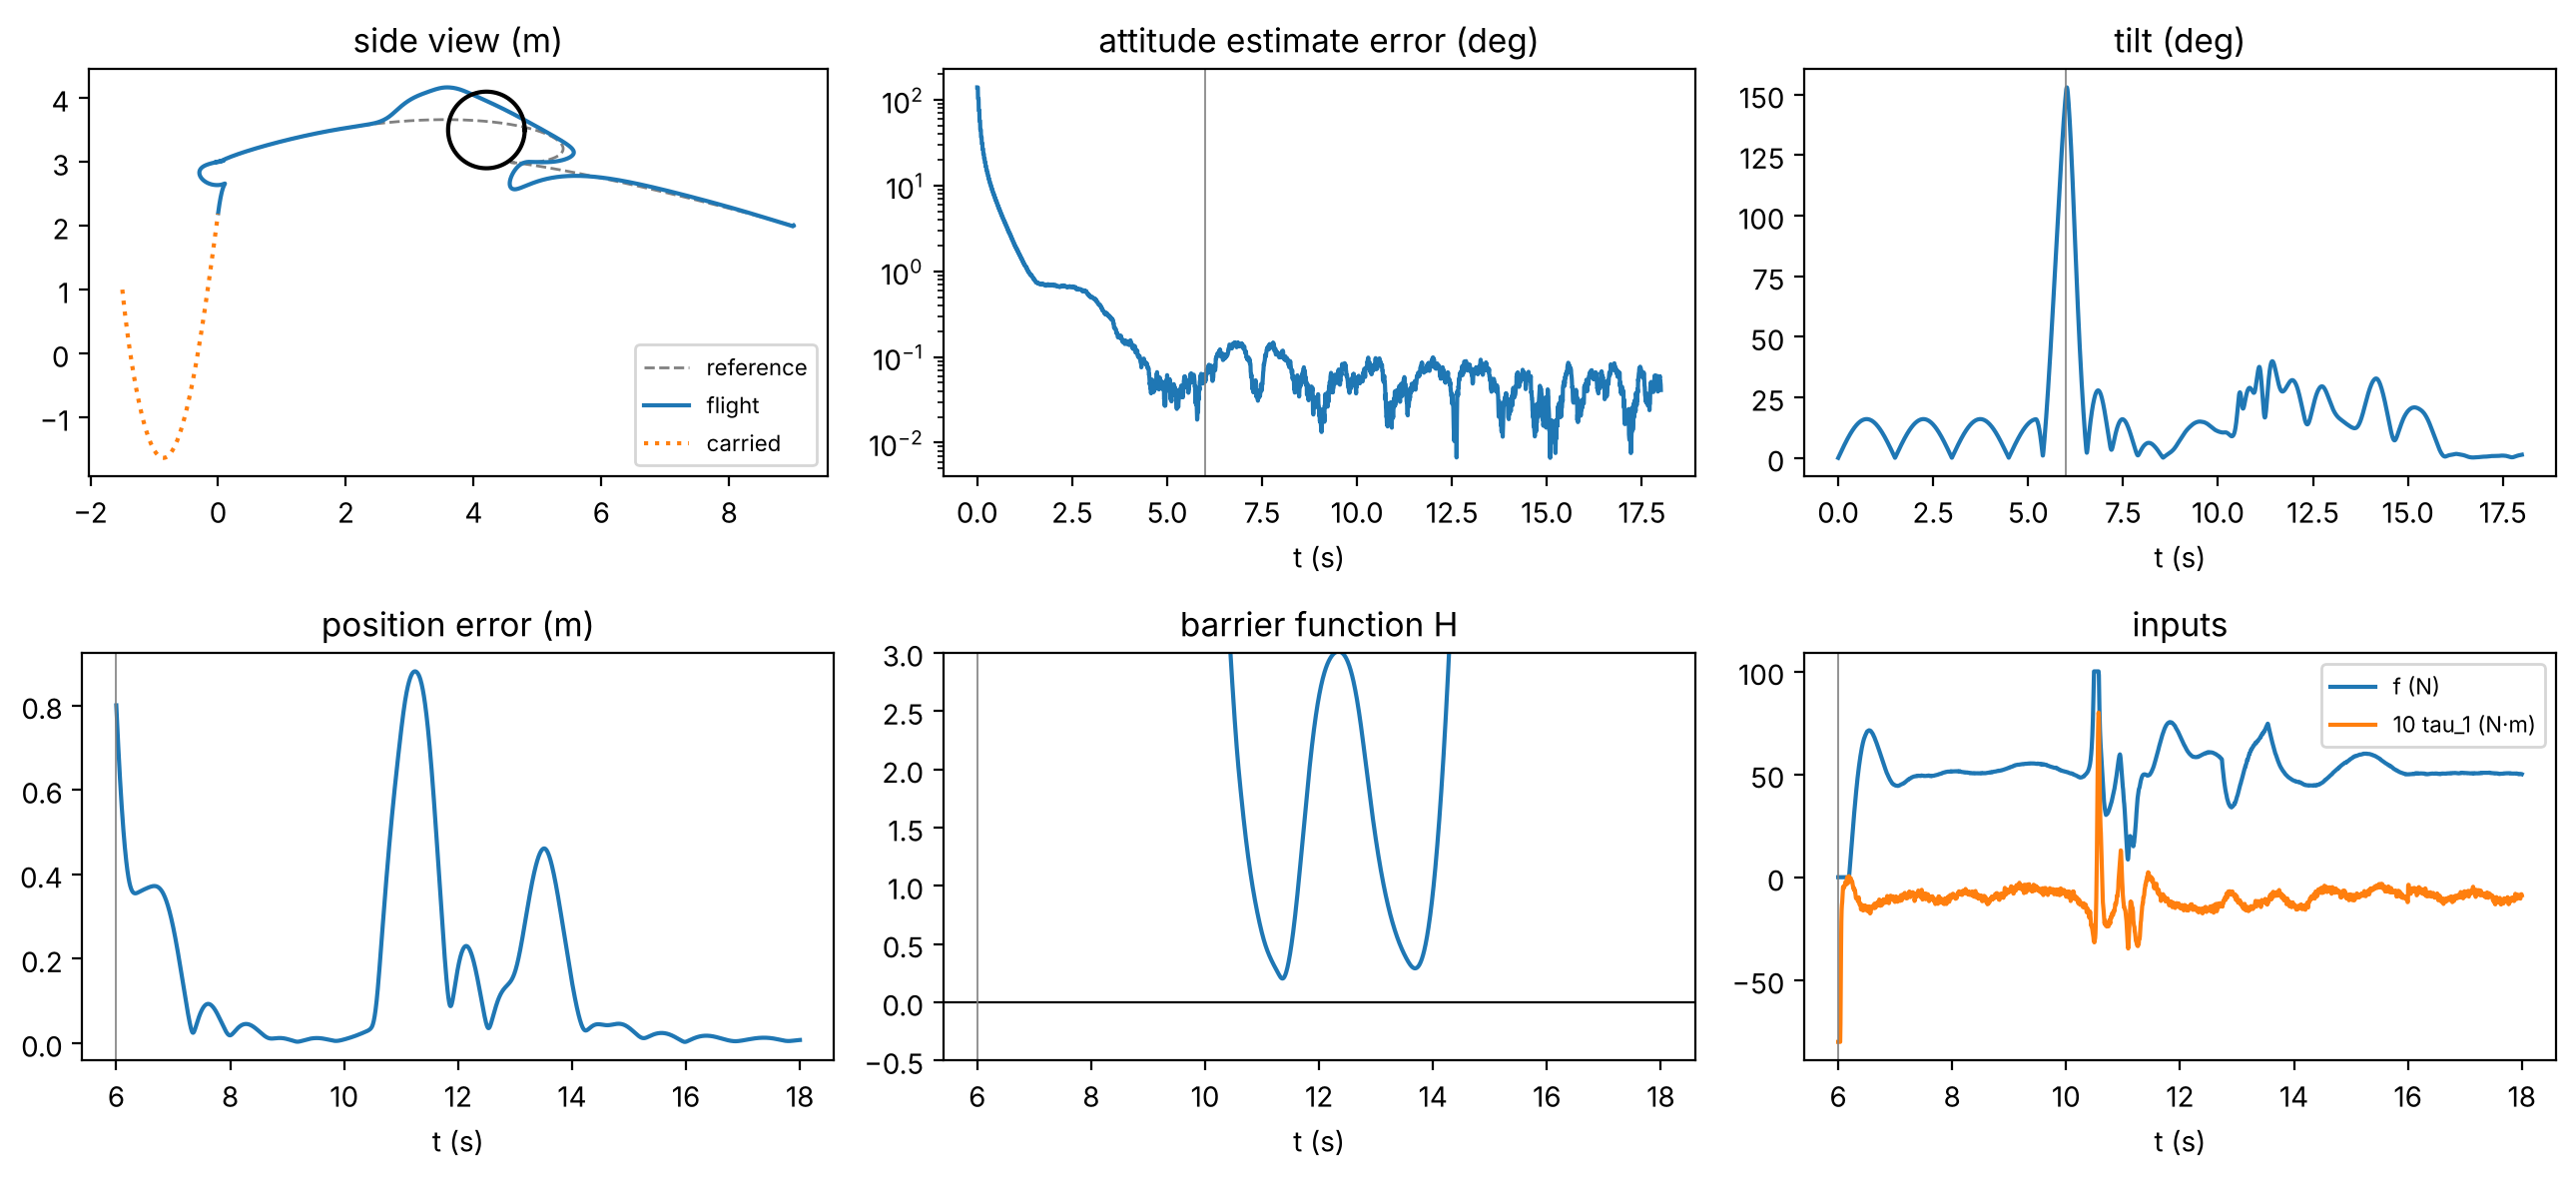

In [13]:
# --- run
t = full["t"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
ax[0, 0].plot(full["xd"][:, 0], full["xd"][:, 2], "--", color="gray", lw=1, label="reference")
ax[0, 0].plot(full["x"][j:, 0], full["x"][j:, 2], label="flight")
ax[0, 0].plot(full["x"][:j, 0], full["x"][:j, 2], ":", label="carried")
th = np.linspace(0, 2 * np.pi, 100)
ax[0, 0].plot(ms.x_o[0] + ms.r_o * np.cos(th), ms.x_o[2] + ms.r_o * np.sin(th), "k")
ax[0, 0].set_aspect("equal"), ax[0, 0].legend(fontsize=8), ax[0, 0].set_title("side view (m)")
ax[0, 1].semilogy(t, np.degrees(full["att_err"]) + 1e-3), ax[0, 1].set_title("attitude estimate error (deg)")
ax[0, 2].plot(t, np.degrees(full["tilt"])), ax[0, 2].set_title("tilt (deg)")
ax[1, 0].plot(t[j:], full["e_x"][j:]), ax[1, 0].set_title("position error (m)")
ax[1, 1].plot(t[j:], full["H"][j:]), ax[1, 1].set_ylim(-0.5, 3), ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_title("barrier function H")
ax[1, 2].plot(t[j:], full["f"][j:], label="f (N)"), ax[1, 2].plot(t[j:], 10 * full["tau"][j:, 0], label="10 tau_1 (N·m)")
ax[1, 2].legend(fontsize=8), ax[1, 2].set_title("inputs")
for a in ax.ravel()[1:]:
    a.axvline(ms.t_carry, color="gray", lw=0.6)
    a.set_xlabel("t (s)")
plt.tight_layout()

The filter alone. While the vehicle is in the operator's hand nothing depends on the estimate,
so this is the filter evaluated against the truth, from an initial error of 140°.

In [14]:
# --- run
for T in (0.0, 0.5, 1.0, 2.0, 4.0, 6.0):
    i = int(round(T / ms.h))
    print("t = %.1f s: attitude error %7.2f deg, position error %.3f m, NEES %9.1f"
          % (T, np.degrees(full["att_err"][i]), full["pos_err"][i], full["nees"][i]))
print("in flight: mean NEES %.2f, largest attitude error %.2f deg, largest position error %.3f m"
      % (full["nees"][j:].mean(), np.degrees(full["att_err"][j:].max()), full["pos_err"][j:].max()))

t = 0.0 s: attitude error  140.00 deg, position error 2.062 m, NEES       0.3
t = 0.5 s: attitude error    6.46 deg, position error 0.473 m, NEES    7600.2
t = 1.0 s: attitude error    1.93 deg, position error 0.078 m, NEES    2793.4
t = 2.0 s: attitude error    0.68 deg, position error 0.096 m, NEES     178.3
t = 4.0 s: attitude error    0.14 deg, position error 0.007 m, NEES       6.2
t = 6.0 s: attitude error    0.05 deg, position error 0.011 m, NEES      15.2
in flight: mean NEES 1.84, largest attitude error 0.15 deg, largest position error 0.023 m


## 10. Take a block out

The same mission with one block removed at a time. Each row is one flight.

In [15]:
# --- run
rows = {
    "everything on": {},
    "truth instead of estimate": dict(estimate=False),
    "no feedforward": dict(feedforward="zero"),
    "no adaptation": dict(adapt=False),
    "no safety filter": dict(safety=False),
    "predictor not told": dict(adapt="untold"),
    "barrier not informed": dict(safety="blind"),
}
print("%-28s %8s %8s %8s %8s %8s" % ("", "RMS cm", "hover cm", "dist m", "min H", "f peak"))
for name, blocks in rows.items():
    s = summary(fly(ms, plan, **blocks), window)
    print("%-28s %8.1f %8.1f %8.3f %8.3f %8.1f"
          % (name, 100 * s["track_rms"], 100 * s["hover"], s["min_dist"], s["min_H"], s["f_peak"]))

                               RMS cm hover cm   dist m    min H   f peak


everything on                     2.2      0.9    0.862    0.203    100.0


truth instead of estimate         1.9      0.1    0.875    0.223    100.0


no feedforward                    6.9      1.4    0.848    0.264    100.0


no adaptation                     5.1      4.4    0.683   -0.016    100.0


no safety filter                  1.4      0.9    0.139   -0.565     71.4


predictor not told                2.1      0.9    0.228   -0.490     75.4


barrier not informed              2.1      0.9    0.691   -0.004    100.0


## Starting points for the exercises

Every exercise of the chapter is a change to `Mission` or to the blocks of `fly`.

In [16]:
# --- run
# Exercise 1: a faster course. Check the plan first, then fly it.
fast = replace(ms, t_course=5.0)
fplan = Plan(fast)
tilt = max(np.degrees(np.arccos(fplan(t)[1]["R"][2, 2])) for t in np.arange(fast.t_start, fast.t_start + 5, 0.02))
print("5 s course: the flat map asks for a tilt of %.0f deg" % tilt)

# Exercise 2: move the obstacle onto the reference and watch H.
head_on = replace(ms, x_o=plan(11.0)[0][0])
print("obstacle centered on the reference at t = 11 s:", np.round(head_on.x_o, 2))

# Exercise 3: a heavier package, farther out.
heavy = replace(ms, m_add=1.2, r_add=np.array([0.25, -0.15, -0.05]))
print("offset torque in hover:", np.round(believed(heavy).m * 9.81 * np.cross(E3, true_params(heavy)[1]), 2), "N·m,",
      "projection ball", heavy.Delta_max, "N·m")

# Exercise 4: a worse sensor. Launch only when the innovation statistic is near one.
coarse = replace(ms, every=20, sig_y=0.1)
o = fly(coarse, t_end=coarse.t_carry)
print("landmarks at 10 Hz with 0.1 m of noise: attitude error at release %.2f deg, NEES %.1f"
      % (np.degrees(o["att_err"][-1]), o["nees"][-1]))

# Exercise 5: throw it differently.
other = replace(ms, flip_axis=E2)
o = fly(other, t_end=other.t_start)
print("flip about the pitch axis: lowest point after the release %.2f m" % o["x"][o["n_rel"]:, 2].min())

5 s course: the flat map asks for a tilt of 51 deg
obstacle centered on the reference at t = 11 s: [3.92 1.02 3.65]
offset torque in hover: [ 1.77  2.94 -0.  ] N·m, projection ball 4.0 N·m


landmarks at 10 Hz with 0.1 m of noise: attitude error at release 2.22 deg, NEES 97.7


flip about the pitch axis: lowest point after the release -1.12 m
